In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas import DataFrame
import xgboost as xgb
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix


In [2]:
train_df = pd.read_csv("../data/train_data.csv")
test_df = pd.read_csv("../data/test_data.csv")

In [3]:
train_df = train_df.drop(columns=['price_above_ema9'])

In [4]:
test_df = test_df.drop(columns=['price_above_ema9'])

In [5]:
(train_df.columns)

Index(['grade', 'model_win', 'RSI_signal', 'MACD', 'MACD_signal', 'MACD_hist',
       'MACD_cross', 'BB_width', 'BB_pct', 'ATR_pct', 'Vol_ratio',
       'Dist_from_200MA', 'sma50_above_sma200', 'perfect_bullish_alignment',
       'price_above_sma50', 'rev_pat', 'cont_pat', 'candle_pat',
       'dow_signal_encoded'],
      dtype='object')

In [6]:
X_train = train_df.drop(columns=['model_win'])
y_train = train_df['model_win']
X_test = test_df.drop(columns=['model_win'])
y_test = test_df['model_win']

y_train.shape

(66019,)

In [7]:
len(train_df.columns)

19

In [8]:
print(X_train.dtypes)

grade                          int64
RSI_signal                     int64
MACD                         float64
MACD_signal                  float64
MACD_hist                    float64
MACD_cross                     int64
BB_width                     float64
BB_pct                       float64
ATR_pct                      float64
Vol_ratio                    float64
Dist_from_200MA              float64
sma50_above_sma200             int64
perfect_bullish_alignment      int64
price_above_sma50              int64
rev_pat                      float64
cont_pat                     float64
candle_pat                   float64
dow_signal_encoded             int64
dtype: object


In [9]:
# print(X_train["price_above_ema9"].value_counts(normalize=True))

In [10]:
# print(train_df.groupby("price_above_ema9")["model_win"].mean())

In [11]:
# print(test_df.groupby("price_above_ema9")["model_win"].mean())

In [12]:
# train_df.drop(columns=['price_above_ema9'])
# test_df = train_df.drop(columns=['price_above_ema9'] ,axis=1)

Class balance — losses: 24846, wins: 41173, scale_pos_weight: 0.60
[0]	validation_0-auc:0.61923
[50]	validation_0-auc:0.62352
[100]	validation_0-auc:0.62377
[150]	validation_0-auc:0.62435
[200]	validation_0-auc:0.62446
[250]	validation_0-auc:0.62475
[299]	validation_0-auc:0.62479

Test AUC: 0.6248

Classification report:
              precision    recall  f1-score   support

           0       0.55      0.63      0.59     11848
           1       0.63      0.55      0.58     13307

    accuracy                           0.59     25155
   macro avg       0.59      0.59      0.59     25155
weighted avg       0.59      0.59      0.59     25155


Confusion matrix:
[[7482 4366]
 [6024 7283]]

Top 15 features:
BB_pct                       0.293739
ATR_pct                      0.113814
BB_width                     0.052775
MACD_cross                   0.049275
candle_pat                   0.047358
RSI_signal                   0.044986
perfect_bullish_alignment    0.041231
price_above_sma50   

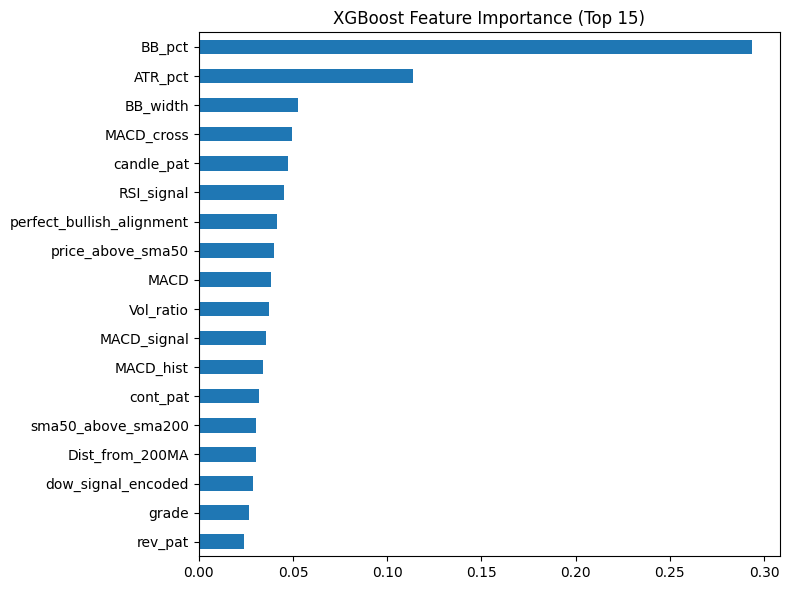

In [13]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"Class balance — losses: {neg}, wins: {pos}, scale_pos_weight: {scale_pos_weight:.2f}")

# 2. Define and train the model
model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.01,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    early_stopping_rounds=50,   
    random_state=42,
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50  
)


y_pred_proba = model.predict_proba(X_test)[:, 1]  
y_pred = (y_pred_proba >= 0.5).astype(int)

# 4. Evaluate
auc = roc_auc_score(y_test, y_pred_proba)
print(f"\nTest AUC: {auc:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

# 5. Feature importance — what actually mattered
importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nTop 15 features:")
print(importance.head(15))

plt.figure(figsize=(8,6))
importance.sort_values().plot(kind="barh")
plt.title("XGBoost Feature Importance (Top 15)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [14]:
print(f"Best iteration: {model.best_iteration}")
print(f"Best score: {model.best_score}")

Best iteration: 283
Best score: 0.6248480857729126


In [15]:
import joblib

# XGBoost's native format (recommended — portable, doesn't need pickle/sklearn version match)
model.save_model("finscope_xgb_model.json")

# Also save the feature column list — critical, since predict_proba needs exact same columns/order
import json
with open("finscope_xgb_features.json", "w") as f:
    json.dump(list(X_train.columns), f)

# Optional: also save via joblib if you want the full sklearn wrapper (easier .predict_proba calls later)
joblib.dump(model, "finscope_xgb_model.pkl")

['finscope_xgb_model.pkl']

In [16]:
def load_ml_pipeline():
    model = xgb.XGBClassifier()
    model.load_model("finscope_xgb_model.json")
    with open("finscope_xgb_features.json") as f:
        feature_cols = json.load(f)
    return model, feature_cols

def get_ml_win_probability(indicator_row: dict, model, feature_cols: list) -> float:
    X_new = pd.DataFrame([indicator_row]).reindex(columns=feature_cols, fill_value=0)
    prob = model.predict_proba(X_new)[:, 1][0]
    return round(float(prob) * 100, 1)

## Suggested Improvements (added by Claude)

1. **Check `grade` for leakage** — retrain without it and compare AUC. If AUC barely drops, grade wasn't adding independent signal beyond the raw indicators (expected, since grade is derived from them). If AUC drops a lot, grade is carrying information your raw features aren't capturing well, and that's worth understanding why.
2. **Retrain on `trade_win` instead of `model_win`** — it's the label that actually ties to realized return_pct (0.79 vs 0.40 correlation). This is the more decision-relevant target.
3. **Try LightGBM as a second model** — usually handles this kind of tabular, moderately-imbalanced data at least as well as XGBoost, trains faster, and gives a quick sanity check that XGBoost isn't underperforming due to hyperparameters rather than the data's actual ceiling.
4. **Add a simple Logistic Regression baseline** — if it gets close to 0.60+ AUC too, that's further evidence the signal ceiling here is inherently modest rather than a modeling problem (matches what the correlation heatmap already suggested — no strong individual predictors).
5. **Threshold tuning** — 0.5 cutoff is arbitrary; use precision-recall curve to pick a threshold that matches what you actually care about (e.g. higher precision if false positives are costlier for a real recommendation product).


In [17]:

# 1. Check grade for leakage — retrain without it
X_train_no_grade = X_train.drop(columns=['grade'])
X_test_no_grade = X_test.drop(columns=['grade'])

model_no_grade = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.01,
    scale_pos_weight=scale_pos_weight, eval_metric="auc",
    early_stopping_rounds=50, random_state=42,
)
model_no_grade.fit(X_train_no_grade, y_train, eval_set=[(X_test_no_grade, y_test)], verbose=False)

y_pred_proba_ng = model_no_grade.predict_proba(X_test_no_grade)[:, 1]
auc_ng = roc_auc_score(y_test, y_pred_proba_ng)
print(f"AUC WITH grade:    {auc:.4f}")
print(f"AUC WITHOUT grade: {auc_ng:.4f}")
print(f"Difference: {auc - auc_ng:.4f}  (small diff = grade wasn't adding much beyond raw indicators)")


AUC WITH grade:    0.6248
AUC WITHOUT grade: 0.6249
Difference: -0.0001  (small diff = grade wasn't adding much beyond raw indicators)


In [18]:

# 2. Retrain on trade_win instead of model_win
y_train_tw = train_df['trade_win'] if 'trade_win' in train_df.columns else None
y_test_tw = test_df['trade_win'] if 'trade_win' in test_df.columns else None

if y_train_tw is not None:
    neg_tw, pos_tw = (y_train_tw == 0).sum(), (y_train_tw == 1).sum()
    spw_tw = neg_tw / pos_tw
    print(f"trade_win class balance — losses: {neg_tw}, wins: {pos_tw}, scale_pos_weight: {spw_tw:.2f}")

    model_tw = xgb.XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.01,
        scale_pos_weight=spw_tw, eval_metric="auc",
        early_stopping_rounds=50, random_state=42,
    )
    model_tw.fit(X_train, y_train_tw, eval_set=[(X_test, y_test_tw)], verbose=False)
    y_pred_proba_tw = model_tw.predict_proba(X_test)[:, 1]
    y_pred_tw = (y_pred_proba_tw >= 0.5).astype(int)

    print(f"\nAUC predicting trade_win: {roc_auc_score(y_test_tw, y_pred_proba_tw):.4f}")
    print(classification_report(y_test_tw, y_pred_tw))
else:
    print("trade_win column not present in train/test CSVs — add it before running this cell.")


trade_win column not present in train/test CSVs — add it before running this cell.


In [19]:

# 3. LightGBM comparison (pip install lightgbm if not available)
import lightgbm as lgb

lgb_model = lgb.LGBMClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.01,
    scale_pos_weight=scale_pos_weight, random_state=42,
)
lgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], eval_metric='auc',
              callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

y_pred_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]
print(f"LightGBM AUC: {roc_auc_score(y_test, y_pred_proba_lgb):.4f}  (XGBoost AUC was {auc:.4f})")


[LightGBM] [Info] Number of positive: 41173, number of negative: 24846
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001554 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2016
[LightGBM] [Info] Number of data points in the train set: 66019, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.623654 -> initscore=0.505086
[LightGBM] [Info] Start training from score 0.505086
Training until validation scores don't improve for 50 rounds


/Users/deepakbedwal/miniconda3/envs/tf/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [20]:

# 4. Logistic Regression baseline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)
y_pred_proba_lr = logreg.predict_proba(X_test_scaled)[:, 1]
print(f"Logistic Regression AUC: {roc_auc_score(y_test, y_pred_proba_lr):.4f}  (XGBoost AUC was {auc:.4f})")


Logistic Regression AUC: 0.6245  (XGBoost AUC was 0.6248)


Best threshold by F1: 0.302  (default is 0.5)
At that threshold — precision: 0.540, recall: 0.971, f1: 0.694


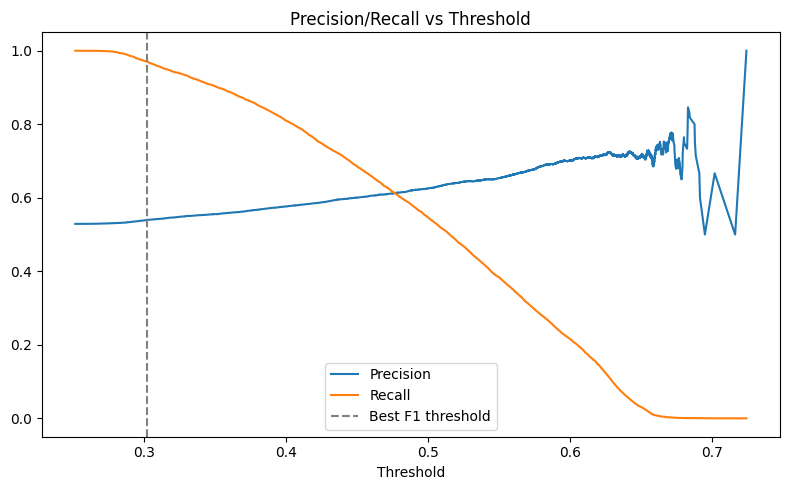

In [21]:

# 5. Threshold tuning via precision-recall curve
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_idx = f1_scores.argmax()
print(f"Best threshold by F1: {thresholds[best_idx]:.3f}  (default is 0.5)")
print(f"At that threshold — precision: {precisions[best_idx]:.3f}, recall: {recalls[best_idx]:.3f}, f1: {f1_scores[best_idx]:.3f}")

plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(thresholds[best_idx], color='gray', linestyle='--', label='Best F1 threshold')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision/Recall vs Threshold')
plt.tight_layout()
plt.savefig('threshold_tuning.png', dpi=150)
plt.show()


## Feature Engineering: New Signals to Test

Two categories below:
- **A) Derivable right now** from columns already in train_data.csv — no extra data needed, interaction/ratio features from what you have.
- **B) Needs raw time-series data** (per-symbol, per-date history) — momentum, relative-strength-vs-sector, and volume trend genuinely need the underlying OHLCV/indicator history sorted by symbol+date, not just this snapshot file. If you have `all_raw_data.csv` or similar with `date`+`symbol` columns, use section B; otherwise skip it for now and just test section A.


In [22]:

# A) Interaction / composite features derivable from existing columns — no extra data needed

X_train_fe = X_train_no_grade.copy()
X_test_fe = X_test_no_grade.copy()

for df_fe in [X_train_fe, X_test_fe]:
    # Trend + momentum agreement: does MACD histogram agree with RSI direction?
    df_fe['macd_rsi_agree'] = ((df_fe['MACD_hist'] > 0).astype(int) == (df_fe['RSI_signal'] > 0).astype(int)).astype(int)

    # Volatility-adjusted BB position: how extreme is BB_pct relative to how wide the bands are
    df_fe['bb_pct_x_width'] = df_fe['BB_pct'] * df_fe['BB_width']

    # Pattern confluence: how many of the three pattern signals agree in bullish direction
    df_fe['pattern_confluence'] = (
        (df_fe['rev_pat'] > 0).astype(int) +
        (df_fe['cont_pat'] > 0).astype(int) +
        (df_fe['candle_pat'] > 0).astype(int)
    )

    # Trend alignment count: how many trend conditions are simultaneously true
    df_fe['trend_alignment_count'] = (
        df_fe['sma50_above_sma200'] +
        df_fe['perfect_bullish_alignment'] +
        df_fe['price_above_sma50']
    )

    # Volume-confirmed volatility: high volume ratio alongside high ATR = real move, not noise
    df_fe['vol_atr_confirm'] = df_fe['Vol_ratio'] * df_fe['ATR_pct']

print("New features added:", [c for c in X_train_fe.columns if c not in X_train_no_grade.columns])
X_train_fe.head()


New features added: ['macd_rsi_agree', 'bb_pct_x_width', 'pattern_confluence', 'trend_alignment_count', 'vol_atr_confirm']


,RSI_signal,MACD,MACD_signal,MACD_hist,MACD_cross,BB_width,BB_pct,ATR_pct,Vol_ratio,Dist_from_200MA,...,price_above_sma50,rev_pat,cont_pat,candle_pat,dow_signal_encoded,macd_rsi_agree,bb_pct_x_width,pattern_confluence,trend_alignment_count,vol_atr_confirm
0,2,1.12,0.85,0.27,0,16.84,0.94,5.11,0.61,34.66,...,1,0.00,0.85,-0.80,0,1,15.8296,1,3,3.1171
1,2,4.75,3.75,1.01,0,24.65,0.86,4.08,0.80,4.29,...,1,-1.00,1.00,0.55,-1,1,21.1990,2,1,3.2640
2,2,-0.27,-3.10,2.84,0,32.27,0.83,6.23,0.87,34.58,...,1,0.00,-1.00,0.55,0,1,26.7841,1,2,5.4201
3,2,2.50,6.50,-4.00,0,4.02,0.45,2.66,0.70,-3.22,...,1,-0.75,0.90,0.00,-1,0,1.8090,1,1,1.8620
4,2,9.90,4.50,5.40,0,14.87,0.92,3.12,2.64,1.03,...,1,0.50,1.00,0.80,-1,1,13.6804,3,1,8.2368


In [23]:

# Retrain XGBoost with the new engineered features (still predicting model_win — swap y_train for y_train_tw to test on trade_win too)

model_fe = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.01,
    scale_pos_weight=scale_pos_weight, eval_metric="auc",
    early_stopping_rounds=50, random_state=42,
)
model_fe.fit(X_train_fe, y_train, eval_set=[(X_test_fe, y_test)], verbose=False)

y_pred_proba_fe = model_fe.predict_proba(X_test_fe)[:, 1]
y_pred_fe = (y_pred_proba_fe >= 0.5).astype(int)

print(f"AUC baseline (no grade):        {auc_ng:.4f}")
print(f"AUC with engineered features:   {roc_auc_score(y_test, y_pred_proba_fe):.4f}")
print()
print(classification_report(y_test, y_pred_fe))

importance_fe = pd.Series(model_fe.feature_importances_, index=X_train_fe.columns).sort_values(ascending=False)
print("\nTop 10 features (with engineered ones):")
print(importance_fe.head(10))


AUC baseline (no grade):        0.6249
AUC with engineered features:   0.6259

              precision    recall  f1-score   support

           0       0.56      0.63      0.59     11848
           1       0.63      0.56      0.59     13307

    accuracy                           0.59     25155
   macro avg       0.59      0.59      0.59     25155
weighted avg       0.59      0.59      0.59     25155


Top 10 features (with engineered ones):
bb_pct_x_width               0.356802
BB_pct                       0.081780
ATR_pct                      0.055179
RSI_signal                   0.048370
price_above_sma50            0.038203
candle_pat                   0.035093
vol_atr_confirm              0.034997
MACD_cross                   0.032412
Vol_ratio                    0.030367
perfect_bullish_alignment    0.029208
dtype: float32


### B) Needs raw time-series data (per symbol, sorted by date) — run only if you have that source file

If you have a file with `date`, `symbol`, and daily indicator values (e.g. `all_raw_data.csv` from the exploration notebook, BEFORE it was collapsed into one row per trade), these are worth computing:
- **RSI/MACD rate of change**: `RSI_signal.diff()` per symbol over last 3-5 days — is momentum building or fading, not just current level
- **Relative strength vs sector**: `stock_return_5d - sector_avg_return_5d` — is it beating its peers today
- **Volume trend**: `Vol_ratio` trend over last 3 days, not just the snapshot value
- **Multi-timeframe agreement**: daily signal vs weekly-resampled signal for the same stock

These need a join/merge back to raw historical data by `symbol` + `date`, which isn't possible from `train_data.csv`/`test_data.csv` alone. Skip this section unless you have that source file — paste its columns here and I'll write the exact merge/feature code.
